# Adversarial Search: Solving Tic-Tac-Toe with Heuristic Alpha-Beta Tree Search

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

In [ ]:
# Hàm phụ: cho tác tử đấu random_player 100 ván khi đi trước (x) và 100 ván khi đi sau (o), đo thời gian mỗi nước
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tictactoe import other
np.random.seed(0)

def danh_gia(agent, ten, N = 100):
    dong = []
    for vai in 'xo':
        t = []
        def dem(board, player = 'x'):
            s = time.perf_counter(); a = agent(board, player); t.append(time.perf_counter() - s); return a
        r = play(dem, random_player, N) if vai == 'x' else play(random_player, dem, N)
        dong.append([ten, 'đi trước' if vai == 'x' else 'đi sau', r[vai], r['d'], r[other(vai)], round(1000 * np.mean(t), 1)])
    return pd.DataFrame(dong, columns = ['Tác tử', 'Vai', 'Thắng', 'Hòa', 'Thua', 'ms/nước'])

def ve(bang, tieu_de):
    nhan = bang['Tác tử'] + ' (' + bang['Vai'] + ')'
    ax = bang[['Thắng', 'Hòa', 'Thua']].set_index(nhan).plot.barh(stacked = True, color = ['#2a78d6', '#c3c2b7', '#eb6834'], figsize = (8, 0.45 * len(bang) + 1.3))
    ax.set_xlabel('số ván'); ax.set_ylabel(''); ax.set_title(tieu_de); ax.invert_yaxis()
    ax.legend(ncol = 3, loc = 'upper center', bbox_to_anchor = (0.5, -0.2))
    plt.show()

In [ ]:
# Bốn trạng thái kiểm thử (đến lượt x đi)
def ban(x = (), o = ()):
    b = empty_board()
    for i in x: b[i] = 'x'
    for i in o: b[i] = 'o'
    return b

tests = {'A: x sắp thắng': ban((0, 4), (1, 3)), 'B: x phải đi ô 7': ban((0, 2), (1, 4)),
         'C: bất lợi': ban((2,), (0, 8)), 'D: bàn rỗng': ban()}

# Heuristic Alpha-Beta Tree Search

See AIMA page 156ff. 


## Heuristic Evaluation Function

In [5]:
import numpy as np

def eval_fun(state, player = 'x'):
    """heuristic for utility of state. Returns score for a node:
    1. For terminal states it returns the utility. 
    2. For non-terminal states, it calculates a weighted linear function using features of the state. 
    The features we look at are 2 in a row/col/diagonal where the 3rd square is empty. We assume that
    the more of these positions we have, the higher the chance of winning.
    We need to be careful that the utility of the heuristic stays between [-1,1]. 
    Note that the largest possible number of these positions is 2. I weigh the count by 0.4, 
    guaranteeing that is in the needed range.
    
    Function Returns: heuristic value, terminal?"""
    
    # terminal state?
    u = utility(state, player)
    if u is not None: return u, True
      
    score = 0
    board = np.array(state).reshape((3,3))
    diagonals = np.array([[board[i][i] for i in range(len(board))], 
                          [board[i][len(board)-i-1] for i in range(len(board))]])
    
    for a_board in [board, np.transpose(board), diagonals]:
        for row in a_board:
            if sum(row == player) == 2 and any(row ==' '): score += .4
            if sum(row == other(player)) == 2 and any(row ==' '): score -= .4
    
    return score, False

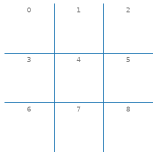

eval for x: (0, False)
eval for o: (0, False)


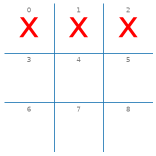

eval for x: (1, True)
eval for o: (-1, True)


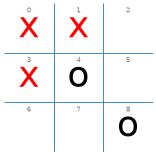

eval for x: (0.8, False)
eval for o: (-0.8, False)


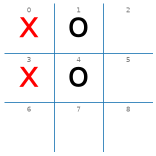

eval for x: (0.0, False)
eval for o: (0.0, False)


In [6]:
board = empty_board() 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[2] = 'x' 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[3] = 'x' 
board[4] = 'o'
board[8] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'x' 
board[4] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

## Search with Cutoff

We add a cutoff to the Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning (see AIMA page 156ff). We use the heuristic evaluation function and the back-up the value using minimax search with alpha-beta pruning to determine the next move.

In [7]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, cutoff = None, player = 'x'):
    """start the search. cutoff = None is minimax search with alpha-beta pruning."""
    global DEBUG, COUNT
    COUNT = 0

    value, move = max_value_ab(board, player, -math.inf, +math.inf, 0, cutoff)
    
    if DEBUG >= 1: print(f"Number of nodes searched (cutoff = {cutoff}): {COUNT}") 
    
    return {"move": move, "value": value}

def max_value_ab(state, player, alpha, beta, depth, cutoff):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta, depth, cutoff):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta, depth + 1, cutoff)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move
    
    return v, move

## Some Tests

### x is about to win (play 8)

Board:


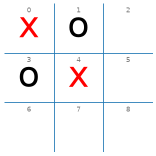


Number of nodes searched (cutoff = 2): 13


{'move': 8, 'value': 1}

CPU times: total: 0 ns
Wall time: 5.74 ms

Number of nodes searched (cutoff = 4): 47


{'move': 2, 'value': 1}

CPU times: total: 15.6 ms
Wall time: 12.5 ms

Number of nodes searched (cutoff = None): 61


{'move': 2, 'value': 1}

CPU times: total: 15.6 ms
Wall time: 11.6 ms


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))

print()
%time display(alpha_beta_search(board, 4))

print()
%time display(alpha_beta_search(board))

### o is about to win

Board:


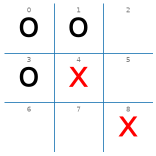


Number of nodes searched (cutoff = 2): 11


{'move': 2, 'value': -1}

CPU times: total: 0 ns
Wall time: 6.22 ms

Number of nodes searched (cutoff = None): 15


{'move': 2, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 6.68 ms


In [9]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board))

### x can draw if it chooses 7

Board:


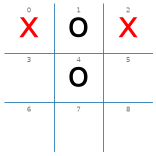


Number of nodes searched (cutoff = 2): 21


{'move': 7, 'value': -0.4}

CPU times: total: 0 ns
Wall time: 8.44 ms

Number of nodes searched (cutoff = 4): 81


{'move': 7, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 14.9 ms

Number of nodes searched (cutoff = None): 101


{'move': 7, 'value': 0}

CPU times: total: 31.2 ms
Wall time: 20.4 ms


In [10]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### Empty board: Only a draw an be guaranteed

Board:


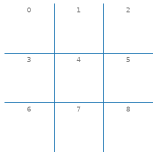


Number of nodes searched (cutoff = 2): 26


{'move': 0, 'value': 0}

CPU times: total: 0 ns
Wall time: 6.47 ms



Number of nodes searched (cutoff = 4): 541


{'move': 4, 'value': 0.0}

CPU times: total: 93.8 ms
Wall time: 91.7 ms



Number of nodes searched (cutoff = None): 18297


{'move': 0, 'value': 0}

CPU times: total: 3.05 s
Wall time: 3.17 s


In [11]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### A bad situation

Board:


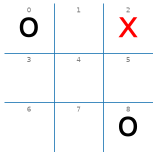


Number of nodes searched (cutoff = 2): 29


{'move': 4, 'value': -0.8}

CPU times: total: 0 ns
Wall time: 7.36 ms

Number of nodes searched (cutoff = 4): 148


{'move': 1, 'value': -1}

CPU times: total: 31.2 ms
Wall time: 20.9 ms

Number of nodes searched (cutoff = None): 238


{'move': 1, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 23.7 ms


In [12]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

## Experiments



### Minimax with Alpha-Beta Pruning vs. Random

In [13]:
def heuristic2_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 2, player = player)["move"]

def heuristic4_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 4, player = player)["move"]

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = None, player = player)["move"]

DEBUG = 1
print("heuristic2 vs. random:")
display(play(heuristic2_player, random_player, N = 3))

heuristic2 vs. random:
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 30
Number of nodes searched (cutoff = 2): 10
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 33
Number of nodes searched (cutoff = 2): 17
Number of nodes searched (cutoff = 2): 7
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 10


{'x': 3, 'o': 0, 'd': 0}

In [14]:
DEBUG = 0
print("heuristic2 vs. random:")
%time display(play(heuristic2_player, random_player))

print("heuristic4 vs. random:")
%time display(play(heuristic4_player, random_player))

print()
print("random vs. heuristic2")
%time display(play(random_player, heuristic2_player))

print("random vs. heuristic4")
%time display(play(random_player, heuristic4_player))

heuristic2 vs. random:


{'x': 93, 'o': 0, 'd': 7}

CPU times: total: 1.33 s
Wall time: 1.35 s
heuristic4 vs. random:


{'x': 96, 'o': 0, 'd': 4}

CPU times: total: 15.9 s
Wall time: 16.2 s

random vs. heuristic2


{'x': 5, 'o': 80, 'd': 15}

CPU times: total: 1.14 s
Wall time: 1.16 s
random vs. heuristic4


{'x': 0, 'o': 85, 'd': 15}

CPU times: total: 8.94 s
Wall time: 9.11 s


### Heuristic vs. Minimax with Alpha-Beta Pruning

In [15]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. alpha_beta")
%time display(play(heuristic2_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic2")
%time display(play(alpha_beta_player, heuristic2_player, N = 1))

print()
print("heuristic4 vs alpha_beta")
%time display(play(heuristic4_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic4")
%time display(play(alpha_beta_player, heuristic4_player, N = 1))

heuristic2 vs. alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 312 ms
Wall time: 311 ms

alpha_beta vs. heuristic2


{'x': 1, 'o': 0, 'd': 0}

CPU times: total: 2.75 s
Wall time: 2.77 s

heuristic4 vs alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 391 ms
Wall time: 403 ms

alpha_beta vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 2.14 s
Wall time: 2.17 s


### Heuristic vs. Heuristic

In [16]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. heuristic4")
%time display(play(heuristic2_player, heuristic4_player, N = 1))

print()
print("heuristic4 vs. heuristic2")
%time display(play(heuristic4_player, heuristic2_player, N = 1))

heuristic2 vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 62.5 ms
Wall time: 58.4 ms

heuristic4 vs. heuristic2


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 141 ms
Wall time: 143 ms


__Idea:__ Start experiments with different boards that already have a few x's and o's randomly placed on them.

,Trạng thái,Cấu hình,Nước đi,Số nút,ms
0,A: x sắp thắng,đầy đủ,2,61,8.7
1,A: x sắp thắng,cutoff = 2,8,13,2.0
2,A: x sắp thắng,cutoff = 4,2,47,6.7
3,B: x phải đi ô 7,đầy đủ,7,101,11.3
4,B: x phải đi ô 7,cutoff = 2,7,21,2.4
5,B: x phải đi ô 7,cutoff = 4,7,81,11.0
6,C: bất lợi,đầy đủ,1,238,24.4
7,C: bất lợi,cutoff = 2,4,29,4.4
8,C: bất lợi,cutoff = 4,1,148,20.1
9,D: bàn rỗng,đầy đủ,0,18297,2135.0


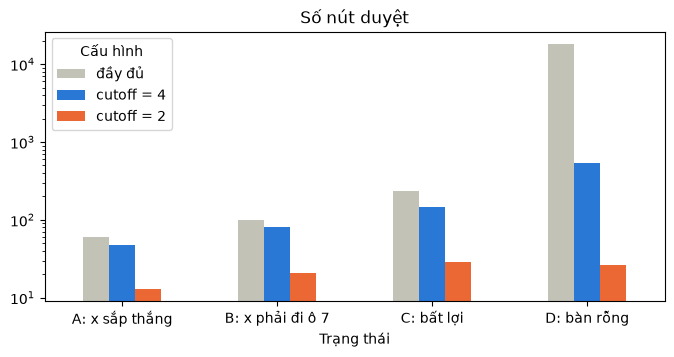

In [ ]:
# Alpha-Beta đầy đủ và heuristic với cutoff = 2, 4 trên các trạng thái kiểm thử
DEBUG = 0
dong = []
for ten, b in tests.items():
    for cutoff in (None, 2, 4):
        t = time.perf_counter(); r = alpha_beta_search(b, cutoff)
        dong.append([ten, 'đầy đủ' if cutoff is None else f'cutoff = {cutoff}', r['move'], COUNT, round(1000 * (time.perf_counter() - t), 1)])
bang = pd.DataFrame(dong, columns = ['Trạng thái', 'Cấu hình', 'Nước đi', 'Số nút', 'ms'])
display(bang)
bang.pivot(index = 'Trạng thái', columns = 'Cấu hình', values = 'Số nút')[['đầy đủ', 'cutoff = 4', 'cutoff = 2']].plot.bar(logy = True, color = ['#c3c2b7', '#2a78d6', '#eb6834'], rot = 0, figsize = (8, 3.5), title = 'Số nút duyệt')
plt.show()

**Nhận xét:** Giảm độ sâu cắt làm số nút giảm mạnh: ở bàn rỗng đầy đủ 18.297 nút, cutoff = 4 còn 541 nút, cutoff = 2 chỉ 26 nút. Ở các trạng thái A, B cutoff = 2 vẫn chọn đúng (A chọn ngay ô 8 thắng ngay, B chọn ô 7); cutoff = 4 gần như giống Alpha-Beta đầy đủ. Ở C (thế đã thua) mọi nước đều như nhau nên nước khác nhau không có nghĩa. Độ sâu lớn hơn cho quyết định đáng tin hơn nhưng tốn nhiều nút và thời gian hơn.

,Tác tử,Vai,Thắng,Hòa,Thua,ms/nước
0,Heuristic cutoff = 2,đi trước,98,2,0,3.2
1,Heuristic cutoff = 2,đi sau,79,14,7,2.8
2,Heuristic cutoff = 4,đi trước,100,0,0,34.2
3,Heuristic cutoff = 4,đi sau,80,20,0,23.6


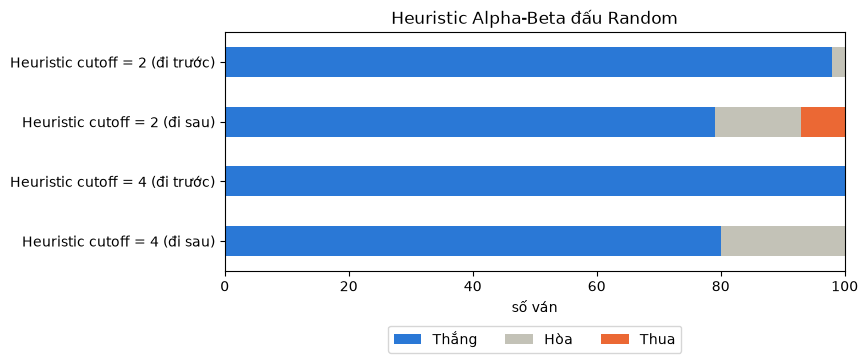

In [ ]:
# Heuristic Alpha-Beta đấu Random
bang = pd.concat([danh_gia(heuristic2_player, 'Heuristic cutoff = 2'), danh_gia(heuristic4_player, 'Heuristic cutoff = 4')], ignore_index = True)
display(bang)
ve(bang, 'Heuristic Alpha-Beta đấu Random')

**Nhận xét:** Cutoff = 4 không thua ván nào (đi trước 100 thắng; đi sau 80 thắng, 20 hòa; ≈ 35 và 25 ms mỗi nước). Cutoff = 2 nhanh hơn rất nhiều (≈ 4 ms) nhưng thua 7 ván khi đi sau. Đây là sự đánh đổi giữa độ sâu và chất lượng quyết định.